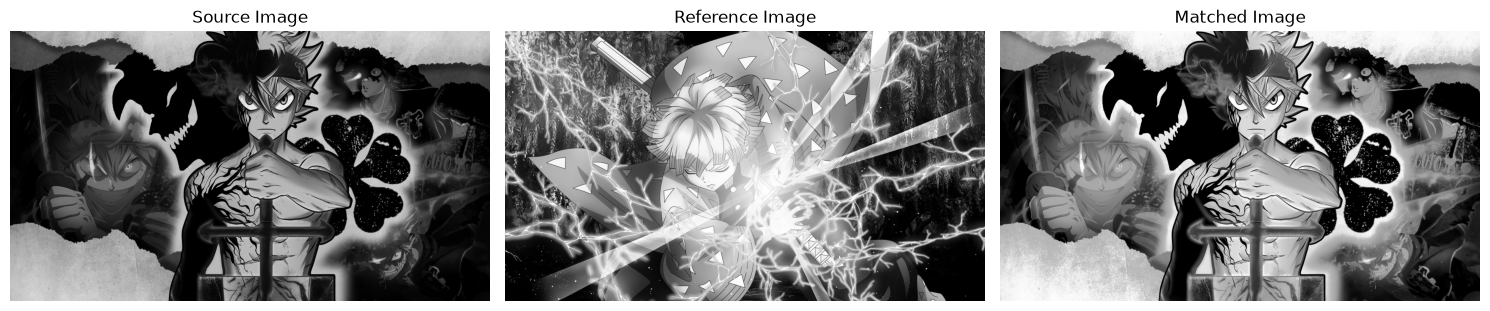

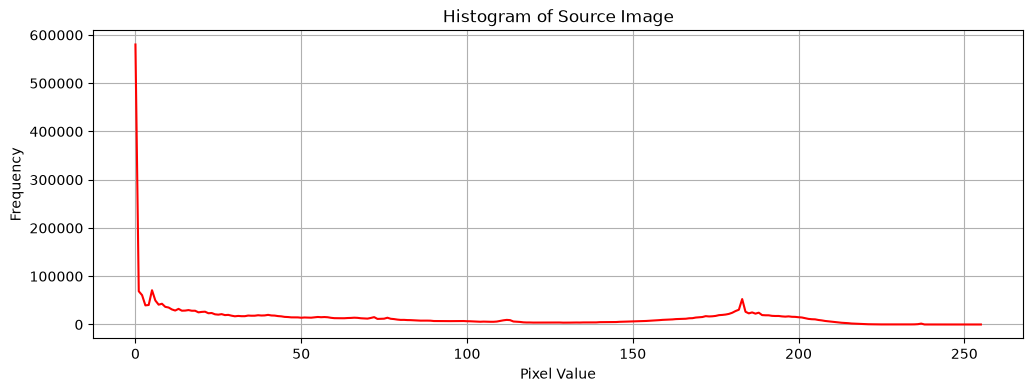

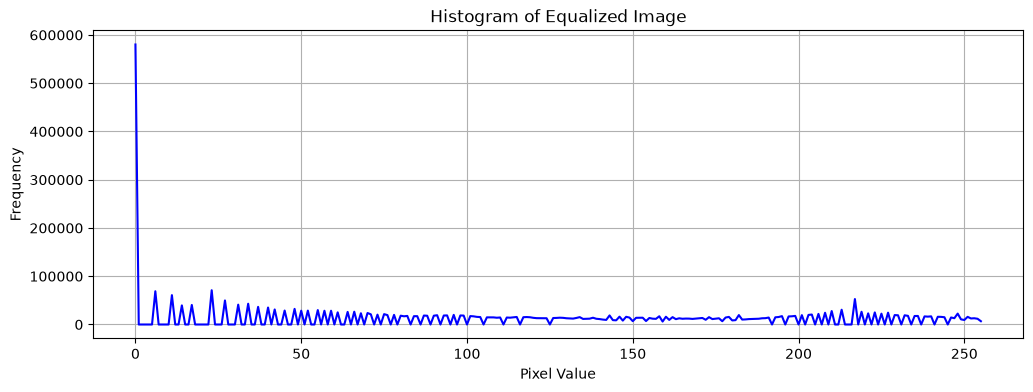

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

source_path = r"C:\Users\DileeP Kumar\OneDrive\Pictures\1294623.png"
reference_path = r"C:\Users\DileeP Kumar\OneDrive\Pictures\Lord Zenitsu.jpg"

src_img = cv2.imread(source_path, cv2.IMREAD_GRAYSCALE)
ref_img = cv2.imread(reference_path, cv2.IMREAD_GRAYSCALE)

if src_img is None or ref_img is None:
    print("Error: Could not load one or both images. Check the file paths.")
else:
    hist_src = cv2.calcHist([src_img], [0], None, [256], [0, 256])
    
    equalized_img = cv2.equalizeHist(src_img)
    hist_eq = cv2.calcHist([equalized_img], [0], None, [256], [0, 256])
    
    src_values, src_indices, src_counts = np.unique(src_img, return_inverse=True, return_counts=True)
    ref_values, ref_counts = np.unique(ref_img, return_counts=True)
    
    src_cdf = np.cumsum(src_counts) / src_counts.sum()
    ref_cdf = np.cumsum(ref_counts) / ref_counts.sum()
    
    src_cdf_scaled = np.round(255 * src_cdf).astype(np.uint8)
    ref_cdf_scaled = np.round(255 * ref_cdf).astype(np.uint8)
    
    mapping = np.zeros(256, dtype=np.uint8)
    for i in range(256):
        if i in src_values:
            src_val = src_cdf_scaled[np.where(src_values == i)[0][0]]
            idx = np.argmin(np.abs(ref_cdf_scaled - src_val))
            mapping[i] = ref_values[idx]
            
    matched_img = mapping[src_img]
    
    plt.figure(figsize=(15, 5))
    
    plt.subplot(1, 3, 1)
    plt.imshow(src_img, cmap='gray')
    plt.title('Source Image')
    plt.axis('off')
    
    plt.subplot(1, 3, 2)
    plt.imshow(ref_img, cmap='gray')
    plt.title('Reference Image')
    plt.axis('off')
    
    plt.subplot(1, 3, 3)
    plt.imshow(matched_img, cmap='gray')
    plt.title('Matched Image')
    plt.axis('off')
    plt.tight_layout()
    plt.show()
    
    plt.figure(figsize=(12, 4))
    plt.plot(hist_src, color='red')
    plt.title('Histogram of Source Image')
    plt.xlabel('Pixel Value')
    plt.ylabel('Frequency')
    plt.grid(True)
    plt.show()
    
    plt.figure(figsize=(12, 4))
    plt.plot(hist_eq, color='blue')
    plt.title('Histogram of Equalized Image')
    plt.xlabel('Pixel Value')
    plt.ylabel('Frequency')
    plt.grid(True)
    plt.show()